In [21]:
import pandas as pd
import numpy as np
df=pd.read_csv('../datasets_globelEnv/Lab2_weather.csv')
df.head()

,Unnamed: 0,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,WindSpeed,Weather,AQI,AQI_Category
0,0,2024-01-01 00:00:00,Station_C,39.967142,73.428050,NaN,17.385882,56.370175,1.258677,16.872084,65.781983,3.195104,Rainy,111.999494,Unhealthy for Sensitive
1,1,2024-01-01 01:00:00,Station_C,38.793738,62.491596,40.556577,22.743510,NaN,0.982323,15.924396,51.618483,1.276158,cloudy,109.110209,Unhealthy for Sensitive
2,2,2024-01-01 02:00:00,STATION_A,51.476885,97.711619,NaN,27.958366,37.279782,1.039817,19.935899,62.911165,8.773654,RAINY,140.340070,Unhealthy for Sensitive
3,3,2024-01-01 03:00:00,Station_D,64.372434,92.734039,50.132296,17.852464,60.408011,1.047789,20.751439,42.309779,2.553534,Cloudy,155.581130,Unhealthy
4,4,2024-01-01 04:00:00,Station_C,NaN,101.462011,57.659714,24.924136,36.624919,0.950957,17.376939,78.646998,0.968020,RAINY,136.651746,Unhealthy for Sensitive


In [22]:
# If dataset contains Unnamed 0: column ,drop it
df.drop(columns='Unnamed: 0',inplace=True)
df.head()

,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,WindSpeed,Weather,AQI,AQI_Category
0,2024-01-01 00:00:00,Station_C,39.967142,73.428050,NaN,17.385882,56.370175,1.258677,16.872084,65.781983,3.195104,Rainy,111.999494,Unhealthy for Sensitive
1,2024-01-01 01:00:00,Station_C,38.793738,62.491596,40.556577,22.743510,NaN,0.982323,15.924396,51.618483,1.276158,cloudy,109.110209,Unhealthy for Sensitive
2,2024-01-01 02:00:00,STATION_A,51.476885,97.711619,NaN,27.958366,37.279782,1.039817,19.935899,62.911165,8.773654,RAINY,140.340070,Unhealthy for Sensitive
3,2024-01-01 03:00:00,Station_D,64.372434,92.734039,50.132296,17.852464,60.408011,1.047789,20.751439,42.309779,2.553534,Cloudy,155.581130,Unhealthy
4,2024-01-01 04:00:00,Station_C,NaN,101.462011,57.659714,24.924136,36.624919,0.950957,17.376939,78.646998,0.968020,RAINY,136.651746,Unhealthy for Sensitive


In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   DateTime      2010 non-null   str    
 1   StationID     2010 non-null   str    
 2   PM2.5         1912 non-null   float64
 3   PM10          2010 non-null   float64
 4   NO2           1909 non-null   float64
 5   SO2           2010 non-null   float64
 6   O3            1909 non-null   float64
 7   CO            2010 non-null   float64
 8   Temperature   1960 non-null   float64
 9   Humidity      2010 non-null   float64
 10  WindSpeed     2010 non-null   float64
 11  Weather       1980 non-null   str    
 12  AQI           2010 non-null   float64
 13  AQI_Category  2010 non-null   str    
dtypes: float64(10), str(4)
memory usage: 220.0 KB


# Handling Missing Values

### Q1: Sort by DateTime to ensure proper temporal imputation


In [24]:
df['DateTime'] = pd.to_datetime(df['DateTime']) # change the datetime to datetime format
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   DateTime      2010 non-null   datetime64[us]
 1   StationID     2010 non-null   str           
 2   PM2.5         1912 non-null   float64       
 3   PM10          2010 non-null   float64       
 4   NO2           1909 non-null   float64       
 5   SO2           2010 non-null   float64       
 6   O3            1909 non-null   float64       
 7   CO            2010 non-null   float64       
 8   Temperature   1960 non-null   float64       
 9   Humidity      2010 non-null   float64       
 10  WindSpeed     2010 non-null   float64       
 11  Weather       1980 non-null   str           
 12  AQI           2010 non-null   float64       
 13  AQI_Category  2010 non-null   str           
dtypes: datetime64[us](1), float64(10), str(3)
memory usage: 220.0 KB


In [25]:
df_processed = df.sort_values(by='DateTime')
df_processed.head()

,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,WindSpeed,Weather,AQI,AQI_Category
0,2024-01-01 00:00:00,Station_C,39.967142,73.428050,NaN,17.385882,56.370175,1.258677,16.872084,65.781983,3.195104,Rainy,111.999494,Unhealthy for Sensitive
1,2024-01-01 01:00:00,Station_C,38.793738,62.491596,40.556577,22.743510,NaN,0.982323,15.924396,51.618483,1.276158,cloudy,109.110209,Unhealthy for Sensitive
2,2024-01-01 02:00:00,STATION_A,51.476885,97.711619,NaN,27.958366,37.279782,1.039817,19.935899,62.911165,8.773654,RAINY,140.340070,Unhealthy for Sensitive
3,2024-01-01 03:00:00,Station_D,64.372434,92.734039,50.132296,17.852464,60.408011,1.047789,20.751439,42.309779,2.553534,Cloudy,155.581130,Unhealthy
4,2024-01-01 04:00:00,Station_C,NaN,101.462011,57.659714,24.924136,36.624919,0.950957,17.376939,78.646998,0.968020,RAINY,136.651746,Unhealthy for Sensitive


In [31]:
df_processed.tail()

,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,WindSpeed,Weather,AQI,AQI_Category
1995,2024-03-24 03:00:00,Station_A,64.843638,102.830229,25.488221,15.623744,66.530957,0.637503,29.854446,76.769431,11.188738,cloudy,155.824428,Unhealthy
1996,2024-03-24 04:00:00,Station_C,57.055295,93.781225,25.346493,16.766428,67.452391,0.929768,27.824329,77.998315,4.745404,clear,151.803050,Unhealthy
1997,2024-03-24 05:00:00,Station_D,50.499770,82.553480,41.203111,18.231714,60.125262,0.561717,29.666160,77.648197,3.088924,RAINY,137.934107,Unhealthy for Sensitive
1998,2024-03-24 06:00:00,station_a,58.369330,93.889285,38.170936,27.887072,48.337492,1.199415,31.556305,71.028201,3.637468,Cloudy,152.481530,Unhealthy
1999,2024-03-24 07:00:00,Station_C,51.869490,102.347329,36.017240,19.797610,79.031193,0.652715,23.159105,70.627467,1.685142,Rainy,141.306785,Unhealthy for Sensitive


In [26]:
print(df_processed.isnull().sum())

DateTime          0
StationID         0
PM2.5            98
PM10              0
NO2             101
SO2               0
O3              101
CO                0
Temperature      50
Humidity          0
WindSpeed         0
Weather          30
AQI               0
AQI_Category      0
dtype: int64


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df_processed.select_dtypes('float').columns
print(numeric_cols)

Index(['PM2.5', 'PM10', 'NO2', 'SO2', 'O3', 'CO', 'Temperature', 'Humidity',
       'WindSpeed', 'AQI'],
      dtype='str')


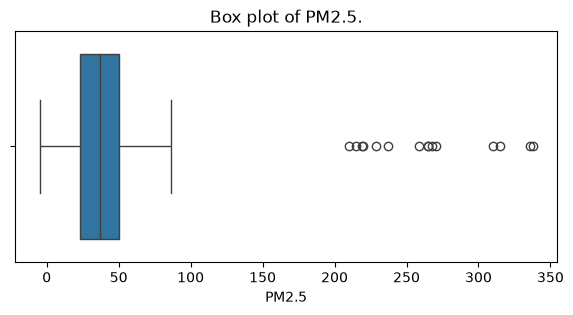

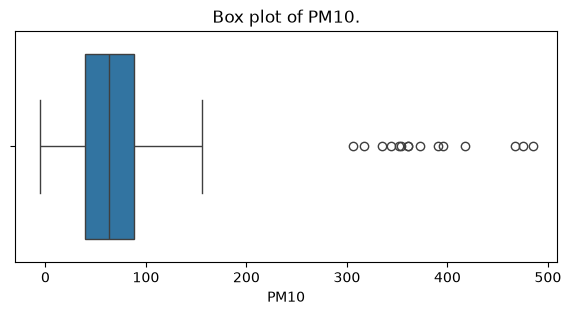

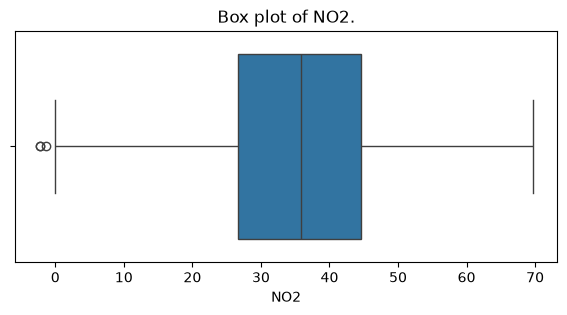

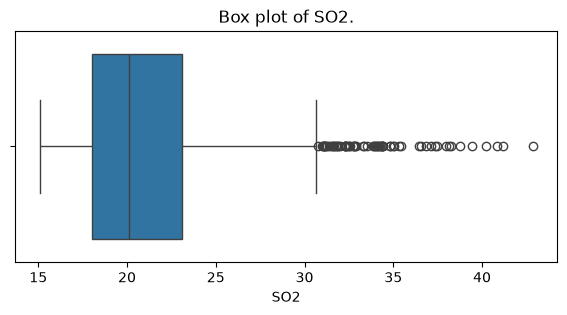

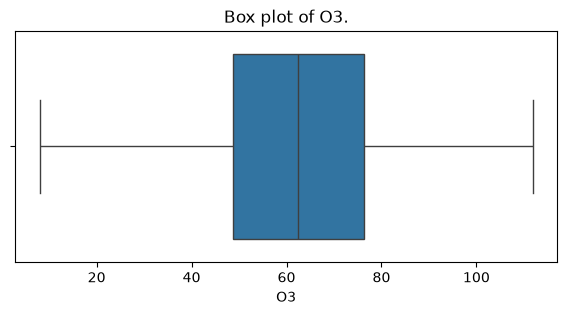

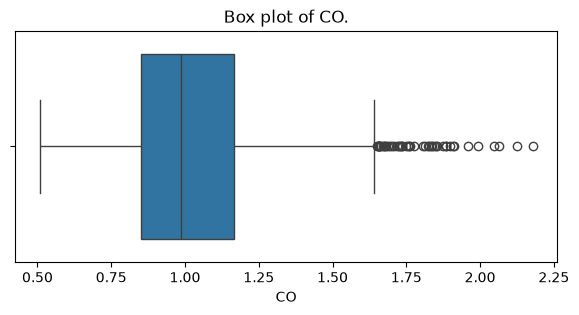

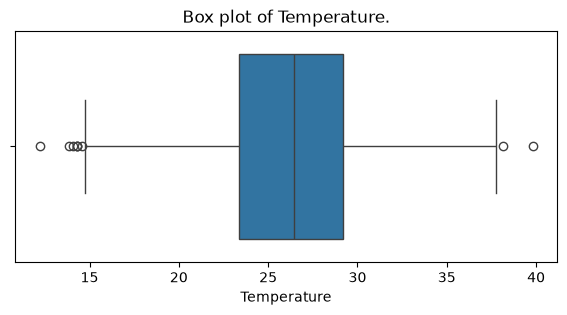

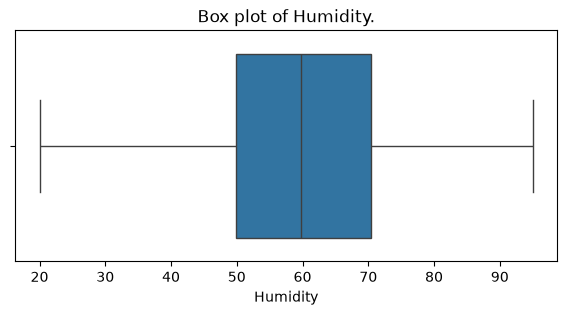

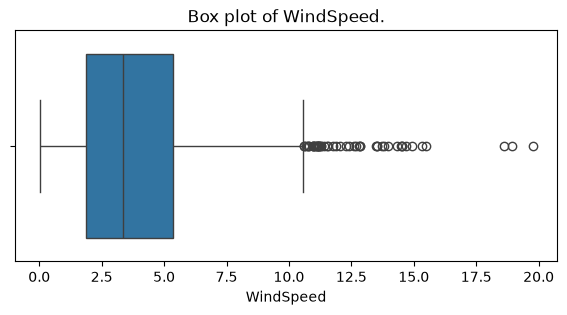

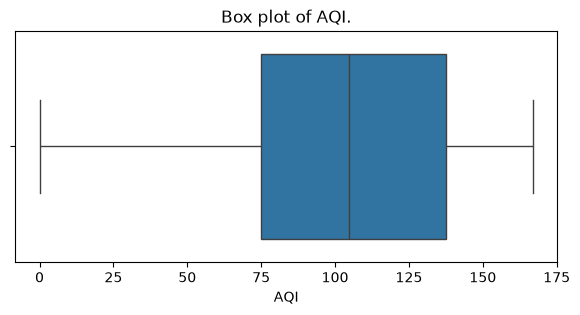

In [28]:
for col in numeric_cols:
    plt.figure(figsize=(7, 3))

    sns.boxplot(data = df_processed, x = col)
    plt.title(f"Box plot of {col}.")

    plt.show()

# Handle pollutant missing values
### Q2 : Pollutant columns are 'PM2.5', 'NO2', 'O3' - Choose the most suitable algorithm to handle missing values and provide the reason for your choice.

In [29]:
import warnings
warnings.filterwarnings('ignore')

In [30]:
pollutant_cols = ['PM2.5', 'NO2', 'O3']
for col in pollutant_cols:
    missing_before = df_processed[col].isnull().sum()
    
    #Fill here
    df_processed[col] = df_processed[col].fillna(df_processed[col].median())
    
    missing_after = df_processed[col].isnull().sum()
    print(f"  {col}: Before : {missing_before} → After: {missing_after} missing values")

  PM2.5: Before : 98 → After: 0 missing values
  NO2: Before : 101 → After: 0 missing values
  O3: Before : 101 → After: 0 missing values


### Q3 : Handle temperature - use most suitble one that can still remain the correct pattern of that data

In [ ]:
missing_before = df_processed['Temperature'].isnull().sum()
# Fill here
df_processed['Temperature']=

missing_after = df_processed['Temperature'].isnull().sum()
print(f"  Temperature: {missing_before} → {missing_after} missing values")


  Temperature: 50 → 0 missing values


### Q4: How can we handle missing values in the Weather column by filling them with the mode (most frequent value) for each hour?

DateTime         object
StationID        object
PM2.5           float64
PM10            float64
NO2             float64
SO2             float64
O3              float64
CO              float64
Temperature     float64
Humidity        float64
WindSpeed       float64
Weather          object
AQI             float64
AQI_Category     object
dtype: object

In [8]:
df_processed['DateTime']=pd.to_datetime(df_processed['DateTime'])
missing_before = df_processed['Weather'].isnull().sum()
df_processed['Hour'] = df_processed['DateTime'].dt.hour

# Fill here

missing_after = df_processed['Weather'].isnull().sum()
print(f"  Weather: {missing_before} → {missing_after} missing values")


  Weather: 30 → 0 missing values


## Datacleaning

### Q5: Remove duplicates based on DateTime and StationID

In [9]:
print(f"\nDuplicates before cleaning: {df_processed.duplicated(subset=['DateTime', 'StationID']).sum()}")
#Fill here
print(f"Duplicates after cleaning: {df_processed.duplicated(subset=['DateTime', 'StationID']).sum()}")



Duplicates before cleaning: 8
Duplicates after cleaning: 0


### Q6:  Standardize values of StationID (case inconsistencies)

In [10]:
print("\nStandardizing StationID...")
print(f"Before: {df_processed['StationID'].unique()}")

#Fill here 

print(f"After: {df_processed['StationID'].unique()}")



Standardizing StationID...
Before: ['Station_C' 'STATION_A' 'Station_D' 'Station_B' 'station_a' 'Station_A']
After: ['STATION_C' 'STATION_A' 'STATION_D' 'STATION_B']


### Q6.1: Standarize Weather (case inconsistencies)

In [11]:
print("\nStandardizing Weather column...")
# Fill here


Standardizing Weather column...
Before: ['Rainy' 'cloudy' 'RAINY' 'Cloudy' 'Clear' 'clear' 'Foggy']


In [12]:
# Fill here
print(f"After: {df_processed['Weather'].unique()}")


After: ['Rainy' 'Cloudy' 'Clear' 'Foggy']


### Q7: Write Python pandas code to identify extreme outliers in pollutant columns using 3*IQR and then clip the values within the valid range.

#### In our DataFrame, we have pollutant columns (PM2.5, PM10, NO2, SO2). Show me code to:

Calculate Q1, Q3, and IQR.

Count how many outliers are present.

Print ranges before and after handling.

Clip the extreme outliers using 3IQR.

In [13]:
print("\nHandling outliers in pollutant measurements...")
for col in ['PM2.5', 'PM10', 'NO2', 'SO2']:
    Q1 = df_processed[col].quantile(0.25)
    Q3 = df_processed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR  # Using 3*IQR for extreme outliers
    upper_bound = Q3 + 3 * IQR
    
    #Fill here
    
    print(f"  {col}: {outliers} outliers detected")
    print(f"    Range before: [{df_processed[col].min():.2f}, {df_processed[col].max():.2f}]")
    
    # Fill here
    print(f"    Range after: [{df_processed[col].min():.2f}, {df_processed[col].max():.2f}]")


Handling outliers in pollutant measurements...
  PM2.5: 15 outliers detected
    Range before: [-5.00, 337.68]
    Range after: [-5.00, 132.95]
  PM10: 15 outliers detected
    Range before: [-5.88, 484.87]
    Range after: [-5.88, 233.27]
  NO2: 0 outliers detected
    Range before: [-2.30, 69.65]
    Range after: [-2.30, 69.65]
  SO2: 6 outliers detected
    Range before: [15.07, 42.86]
    Range after: [15.07, 38.27]


### Q8: How can we extract temporal features such as Year, Month, Day, Hour, and DayOfWeek from a DateTime column in pandas?

In [14]:
# Extract temporal features
print("\nExtracting temporal features from DateTime...")
df_processed['Year'] = df_processed['DateTime'].dt.year
df_processed['Month'] = df_processed['DateTime'].dt.month
df_processed['Day'] = df_processed['DateTime'].dt.day
df_processed['Hour'] = df_processed['DateTime'].dt.hour
df_processed['DayOfWeek'] = df_processed['DateTime'].dt.dayofweek
df_processed['IsWeekend'] = (df_processed['DayOfWeek'] >= 5).astype(int)

# Create time periods
# Fill here

print(f"  Created features: Year, Month, Day, Hour, DayOfWeek, IsWeekend, TimePeriod")



Extracting temporal features from DateTime...
  Created features: Year, Month, Day, Hour, DayOfWeek, IsWeekend, TimePeriod


### Q9: Suppose you have a PM2.5 column in a DataFrame. Write code to categorize it into:

Good (0–12)

Moderate (12.1–35.4)

Sensitive (35.5–55.4)

Unhealthy (55.5–150.4)

VeryUnhealthy (150.5–1000)

In [15]:
print("\nCreating pollution severity categories...")

#Fill here

df_processed.head()


Creating pollution severity categories...


,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,...,AQI,AQI_Category,Hour,Year,Month,Day,DayOfWeek,IsWeekend,TimePeriod,PM2.5_Level
0,2024-01-01 00:00:00,STATION_C,39.967142,73.428050,40.556577,17.385882,56.370175,1.258677,16.872084,65.781983,...,111.999494,Unhealthy for Sensitive,0,2024,1,1,0,0,Night,Sensitive
1,2024-01-01 01:00:00,STATION_C,38.793738,62.491596,40.556577,22.743510,56.370175,0.982323,15.924396,51.618483,...,109.110209,Unhealthy for Sensitive,1,2024,1,1,0,0,Night,Sensitive
2,2024-01-01 02:00:00,STATION_A,51.476885,97.711619,50.132296,27.958366,37.279782,1.039817,19.935899,62.911165,...,140.340070,Unhealthy for Sensitive,2,2024,1,1,0,0,Night,Sensitive
3,2024-01-01 03:00:00,STATION_D,64.372434,92.734039,50.132296,17.852464,60.408011,1.047789,20.751439,42.309779,...,155.581130,Unhealthy,3,2024,1,1,0,0,Night,Unhealthy
4,2024-01-01 04:00:00,STATION_C,38.793738,101.462011,57.659714,24.924136,36.624919,0.950957,17.376939,78.646998,...,136.651746,Unhealthy for Sensitive,4,2024,1,1,0,0,Night,Sensitive


### Q10: Given an AQI_Category column with ordered categories:
['Good', 'Moderate', 'Unhealthy for Sensitive', 'Unhealthy', 'Very Unhealthy']
how can you encode them into integers while preserving the natural order?

In [17]:
# Label Encoding for ordinal categories (AQI_Category has natural order)
print("\nLabel Encoding for AQI_Category (ordinal)...")
aqi_order = ['Good', 'Moderate', 'Unhealthy for Sensitive', 'Unhealthy', 'Very Unhealthy']
# Fill here
print(f"  Mapping: {aqi_mapping}")
df_processed.head()


Label Encoding for AQI_Category (ordinal)...
  Mapping: {'Good': 0, 'Moderate': 1, 'Unhealthy for Sensitive': 2, 'Unhealthy': 3, 'Very Unhealthy': 4}


,DateTime,StationID,PM2.5,PM10,NO2,SO2,O3,CO,Temperature,Humidity,...,AQI_Category,Hour,Year,Month,Day,DayOfWeek,IsWeekend,TimePeriod,PM2.5_Level,AQI_Category_Encoded
0,2024-01-01 00:00:00,STATION_C,39.967142,73.428050,40.556577,17.385882,56.370175,1.258677,16.872084,65.781983,...,Unhealthy for Sensitive,0,2024,1,1,0,0,Night,Sensitive,2
1,2024-01-01 01:00:00,STATION_C,38.793738,62.491596,40.556577,22.743510,56.370175,0.982323,15.924396,51.618483,...,Unhealthy for Sensitive,1,2024,1,1,0,0,Night,Sensitive,2
2,2024-01-01 02:00:00,STATION_A,51.476885,97.711619,50.132296,27.958366,37.279782,1.039817,19.935899,62.911165,...,Unhealthy for Sensitive,2,2024,1,1,0,0,Night,Sensitive,2
3,2024-01-01 03:00:00,STATION_D,64.372434,92.734039,50.132296,17.852464,60.408011,1.047789,20.751439,42.309779,...,Unhealthy,3,2024,1,1,0,0,Night,Unhealthy,3
4,2024-01-01 04:00:00,STATION_C,38.793738,101.462011,57.659714,24.924136,36.624919,0.950957,17.376939,78.646998,...,Unhealthy for Sensitive,4,2024,1,1,0,0,Night,Sensitive,2


In [18]:
df_processed.columns

Index(['DateTime', 'StationID', 'PM2.5', 'PM10', 'NO2', 'SO2', 'O3', 'CO',
       'Temperature', 'Humidity', 'WindSpeed', 'Weather', 'AQI',
       'AQI_Category', 'Hour', 'Year', 'Month', 'Day', 'DayOfWeek',
       'IsWeekend', 'TimePeriod', 'PM2.5_Level', 'AQI_Category_Encoded'],
      dtype='object')